# Trabajo práctico — Ciencia de Datos e Inteligencia Artificial

## Predicción de goles en el fútbol argentino

## 1. Presentación del dataset

El dataset contiene información sobre partidos del fútbol
argentino disputados entre 2015 y 2022.

Nuestro objetivo es predecir la cantidad total de goles
de un partido utilizando información previa al encuentro.

Entonces, la pregunta de investigación es: ¿Es posible predecir la cantidad total de goles de un partido del fútbol argentino a partir de información disponible antes de que comience?

> **Integrantes:** Enzo Martinez, y Juan Ignacio Arguello

## 1. Presentación del dataset

Utilizamos el dataset público **Argentinian football match information 2015–2022**, disponible en [Kaggle](https://www.kaggle.com/datasets/camussonif/argentinian-football-results-20152022).

El archivo elegido es `afa_2015_2022_eng.csv`, que contiene **2.821 partidos** y **34 columnas** antes de crear nuevas variables. Incluye datos del tipo:

- **Categóricas:** torneo (`tournament`), equipo local (`team_home`), visitante (`team_away`) y resultado (`result`).
- **Numéricas:** goles, cuotas de apuestas, valor de los planteles, edad y altura promedio.
- **Temporal:** fecha y hora del encuentro (`game_datetime`).

**incluye** más de 10 columnas, información numérica y categórica, fechas y una variable que permite formular una pregunta de predicción. Usaremos las columnas `goals_home` y `goals_away` para calcular el total real de goles de cada encuentro.

**Importante:** el objetivo es predecir antes del partido. En el momento de entrenar evitaremos usar como entradas los goles y otras estadísticas que solo se conocen durante o después del encuentro.

## 2. Importación de librerías y carga del archivo

Importamos las herramientas utilizadas en clase: `pandas` para tablas, `matplotlib` y `seaborn` para gráficos y `scikit-learn` para regresión.

Para que el notebook pueda ejecutarse de principio a fin, **el CSV tiene que estar en la misma carpeta que este notebook**. También se contempla la carpeta `Downloads` de Windows si el archivo está allí. Si descargaste el paquete ZIP completo, ambos archivos ya vienen juntos.

In [5]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Cargamos los partidos del fútbol argentino desde GitHub
url = "https://raw.githubusercontent.com/juaniargu/TP-Python-para-CDD/refs/heads/main/afa_2015_2022_eng.csv"

df = pd.read_csv(url)

print(f"Dataset cargado: {df.shape}")

Dataset cargado: (2821, 34)


## 3. Primer vistazo a los datos

Mostramos los primeros cinco partidos para entender la estructura de la tabla. Después consultamos su tamaño y los tipos de datos. Esto nos ayuda a comprender su estructura y comprobar que la carga se hizo correctamente y a identificar qué variables contiene.

In [6]:
df.head()

,tournament,week,game,team_home,team_away,goals_home,goals_away,possesion_home,on_target_home,attemps_home,...,lefties_proportion_home,team_value_away,mean_height_away,mean_age_away,lefties_proportion_away,result,game_datetime,odds_home,odds_away,odds_draw
0,Campeonato 2015,1,1,Velez,Aldosivi,2,0,NaN,NaN,NaN,...,0.301887,8.725,1.790370,28.100000,0.233333,H,2015-02-13 18:00:00,1.75,5.01,3.37
1,Campeonato 2015,1,2,Racing Club,Rosario Central,0,1,NaN,NaN,NaN,...,0.297297,18.350,1.789333,25.608696,0.217391,A,2015-02-13 21:10:00,1.80,4.82,3.23
2,Campeonato 2015,1,3,San Lorenzo,Colon,2,0,NaN,NaN,NaN,...,0.285714,12.125,1.801026,24.948718,0.282051,H,2015-02-14 17:00:00,1.70,5.55,3.34
3,Campeonato 2015,1,4,Gimnasia (LP),Def y Justicia,0,1,NaN,NaN,NaN,...,0.227273,12.050,1.776889,25.460000,0.240000,A,2015-02-14 17:00:00,2.06,3.82,3.09
4,Campeonato 2015,1,5,Godoy Cruz,San Martin (SJ),1,1,NaN,NaN,NaN,...,0.226415,11.250,1.780000,26.153846,0.205128,D,2015-02-14 19:15:00,2.03,3.82,3.15


In [7]:
print("Filas (partidos):", df.shape[0])
print("Columnas originales:", df.shape[1])

Filas (partidos): 2821
Columnas originales: 34


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2821 entries, 0 to 2820
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   tournament               2821 non-null   str    
 1   week                     2821 non-null   int64  
 2   game                     2821 non-null   int64  
 3   team_home                2821 non-null   str    
 4   team_away                2821 non-null   str    
 5   goals_home               2821 non-null   int64  
 6   goals_away               2821 non-null   int64  
 7   possesion_home           1496 non-null   float64
 8   on_target_home           1496 non-null   float64
 9   attemps_home             1496 non-null   float64
 10  fouls_home               1496 non-null   float64
 11  corner_kicks_home        1496 non-null   float64
 12  possesion_away           1496 non-null   float64
 13  on_target_away           1496 non-null   float64
 14  attemps_away             1496 non-n

## 3. Calidad de los datos

Antes de hacer predicciones revisamos **tipos de datos, faltantes, duplicados y valores imposibles**, y justificamos las decisiones de limpieza.

La fecha se convierte de texto a formato `datetime`. Después creamos `total_goals` sumando los goles de local y visitante. Esta columna será nuestra `y` y **nunca formará parte de `X`**.

In [9]:
# Transformación de fecha y creación de la variable objetivo
df["game_datetime"] = pd.to_datetime(df["game_datetime"], errors="coerce")
df["total_goals"] = df["goals_home"] + df["goals_away"]

df[["team_home", "team_away", "goals_home", "goals_away", "total_goals"]].head()

,team_home,team_away,goals_home,goals_away,total_goals
0,Velez,Aldosivi,2,0,2
1,Racing Club,Rosario Central,0,1,1
2,San Lorenzo,Colon,2,0,2
3,Gimnasia (LP),Def y Justicia,0,1,1
4,Godoy Cruz,San Martin (SJ),1,1,2


### 3.1 Valores faltantes

Contamos cuántos datos faltan por columna. Esto permite decidir **qué variables se pueden usar** y evitar borrar registros innecesariamente.

In [10]:
# Cantidad y porcentaje de nulos por variable
nulos = df.isna().sum().sort_values(ascending=False)
tabla_nulos = pd.DataFrame({
    "nulos": nulos,
    "porcentaje (%)": (nulos / len(df) * 100).round(2)
})

tabla_nulos[tabla_nulos["nulos"] > 0]

,nulos,porcentaje (%)
on_target_home,1325,46.97
attemps_home,1325,46.97
fouls_home,1325,46.97
fouls_away,1325,46.97
corner_kicks_away,1325,46.97
possesion_away,1325,46.97
possesion_home,1325,46.97
attemps_away,1325,46.97
on_target_away,1325,46.97
corner_kicks_home,1325,46.97


### 3.2 Duplicados

Dos filas idénticas podrían contar el mismo partido dos veces. Las verificamos y, si existen, las eliminamos.

In [11]:
duplicados = df.duplicated().sum()
print("Filas duplicadas:", duplicados)
df = df.drop_duplicates().copy()
print("Filas luego de quitar duplicados:", len(df))

Filas duplicadas: 0
Filas luego de quitar duplicados: 2821


Con esto, hemos documentado problemas y decisiones, en lugar de hacer una limpieza automática que elimine datos útiles.

## 4. EDA univariado: comprender las variables

El **análisis exploratorio univariado** estudia cada variable por separado. Empezamos con estadística descriptiva y luego mostramos histogramas y boxplots.

Nos interesan especialmente `total_goals`, las cuotas (`odds_home`) y el valor de los planteles (`team_value_home`).

Para comprender que buscamos a la hora de analizar cada variable vemos:

`total_goals`: nuestra variable objetivo.

`goals_home` y `goals_away`: para estudiar cómo se distribuyen los goles.

`team_value_home` y `team_value_away`: para investigar si el valor de los planteles se relaciona con los goles.

`odds_home`, `odds_draw` y `odds_away`: para investigar si las expectativas del mercado tienen alguna relación con los goles.

In [12]:
# Estadística descriptiva de las variables principales
df[["total_goals", "goals_home", "goals_away", "odds_home", "team_value_home"]].describe().round(2)

,total_goals,goals_home,goals_away,odds_home,team_value_home
count,2821.00,2821.00,2821.00,2818.00,2821.00
mean,2.28,1.29,0.99,2.41,35.81
std,1.54,1.13,1.04,0.86,30.85
min,0.00,0.00,0.00,1.14,4.40
25%,1.00,0.00,0.00,1.85,14.92
50%,2.00,1.00,1.00,2.22,25.28
75%,3.00,2.00,2.00,2.77,46.42
max,9.00,8.00,6.00,11.25,201.05


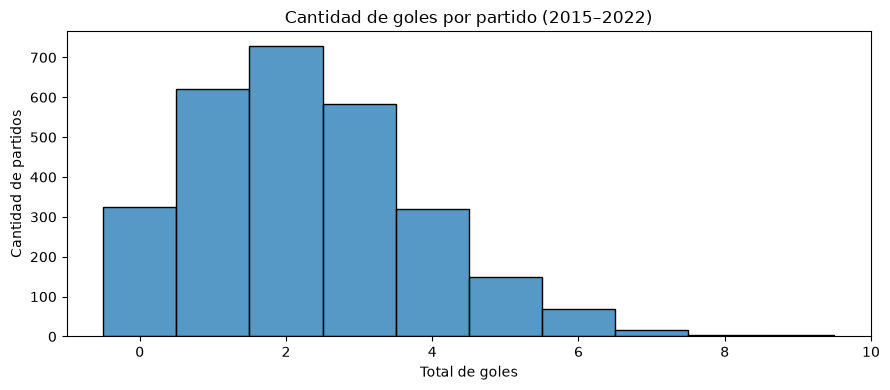

In [13]:
# Distribución de la cantidad total de goles
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="total_goals", discrete=True, color="tab:blue")
plt.title("Cantidad de goles por partido (2015–2022)")
plt.xlabel("Total de goles")
plt.ylabel("Cantidad de partidos")
plt.tight_layout()
plt.show()

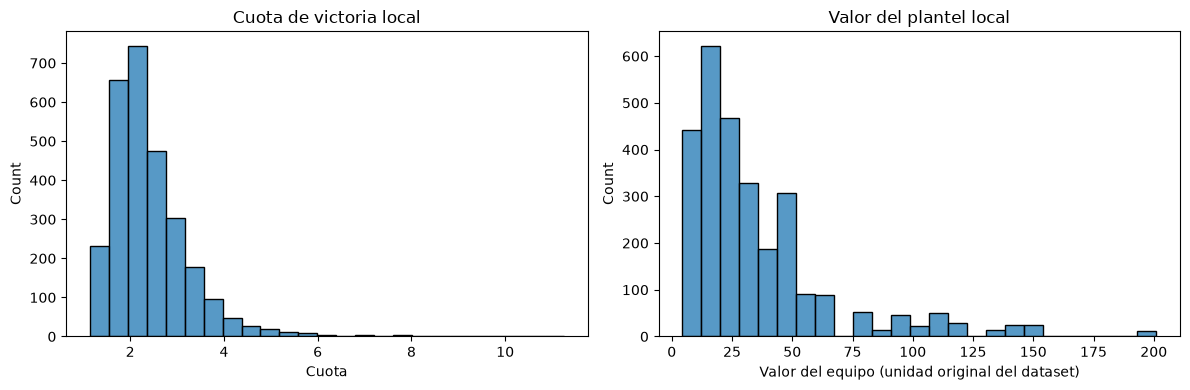

In [14]:
# Histogramas de dos variables explicativas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="odds_home", bins=25, ax=axes[0], color="tab:blue")
axes[0].set_title("Cuota de victoria local")
axes[0].set_xlabel("Cuota")
sns.histplot(data=df, x="team_value_home", bins=25, ax=axes[1], color="tab:blue")
axes[1].set_title("Valor del plantel local")
axes[1].set_xlabel("Valor del equipo (unidad original del dataset)")
plt.tight_layout()
plt.show()

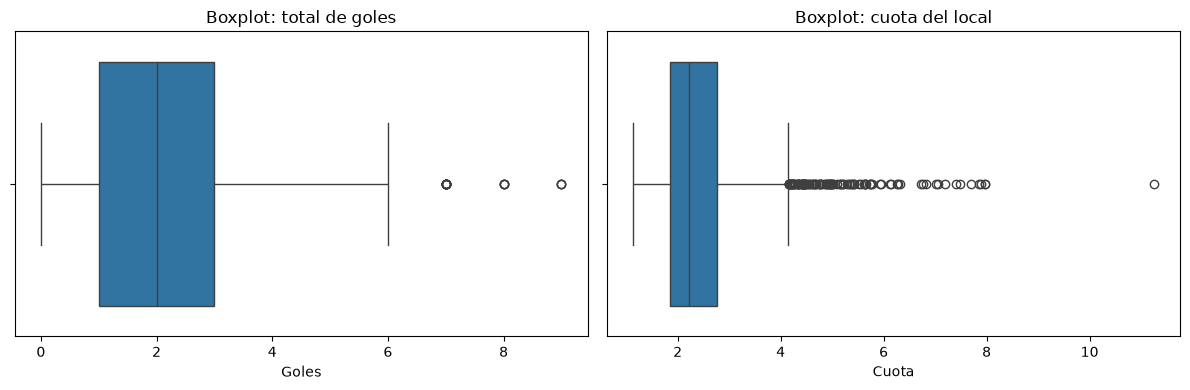

In [15]:
# Boxplots para observar mediana, dispersión y valores extremos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="total_goals", ax=axes[0], color="tab:blue")
axes[0].set_title("Boxplot: total de goles")
axes[0].set_xlabel("Goles")
sns.boxplot(data=df, x="odds_home", ax=axes[1], color="tab:blue")
axes[1].set_title("Boxplot: cuota del local")
axes[1].set_xlabel("Cuota")
plt.tight_layout()
plt.show()

**Lectura del EDA univariado:**

- El total de goles es una **variable discreta**: solo puede tomar números enteros no negativos. Podemos observar que el resultado mas comun es que hayan dos goles donde la mayoría de los partidos tienen una cantidad relativamente baja de goles, mientras que los encuentros con muchos goles son poco frecuentes.
- Un boxplot puede marcar como “atípicos” algunos partidos con muchos goles. **Atípico no significa incorrecto**: conservamos esas observaciones.
- Las cuotas y el valor de los equipos muestran variabilidad, útil para investigar si aportan información a la predicción.

## 5. EDA bivariado: relación con los goles

El análisis bivariado compara dos variables. Haremos **scatterplots** para ver si los goles tienden a variar con las cuotas o con el valor del plantel local. Después calcularemos una matriz de **correlación** para las variables numéricas disponibles antes del partido.

La correlación describe una asociación lineal, **no demuestra causalidad** ni asegura que un modelo pueda predecir bien.

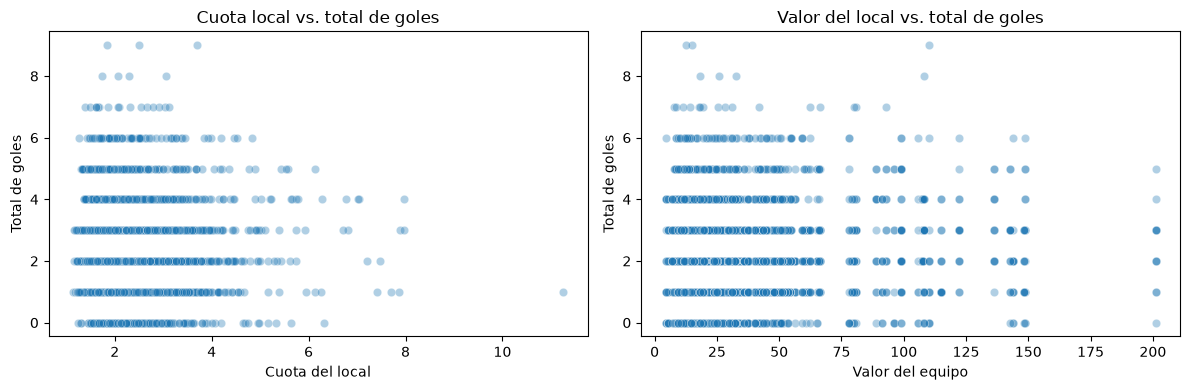

In [16]:
# Scatterplots: variables antes del partido versus total de goles
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="odds_home", y="total_goals", alpha=0.35, ax=axes[0], color="tab:blue")
axes[0].set_title("Cuota local vs. total de goles")
axes[0].set_xlabel("Cuota del local")
axes[0].set_ylabel("Total de goles")
sns.scatterplot(data=df, x="team_value_home", y="total_goals", alpha=0.35, ax=axes[1], color="tab:blue")
axes[1].set_title("Valor del local vs. total de goles")
axes[1].set_xlabel("Valor del equipo")
axes[1].set_ylabel("Total de goles")
plt.tight_layout()
plt.show()

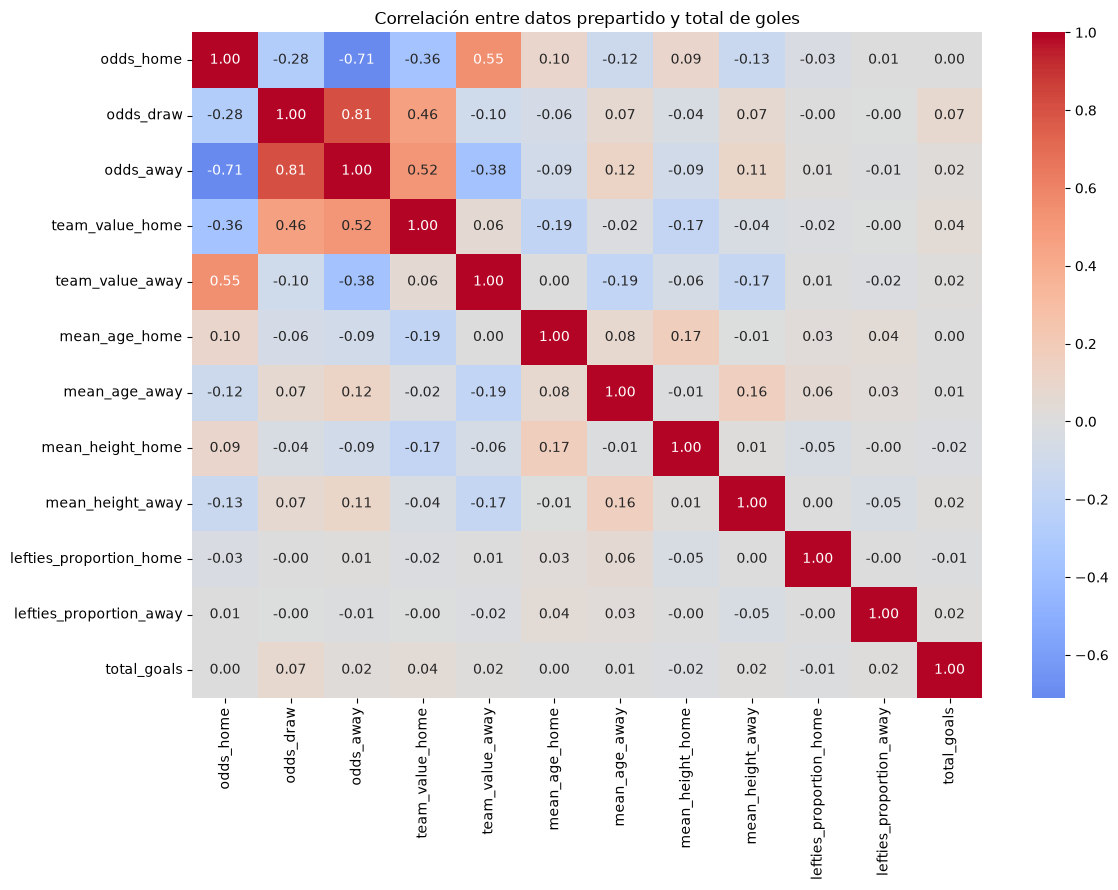

In [17]:
# Variables conocidas antes del partido que exploraremos como predictoras
columnas_x = [
    "odds_home", "odds_draw", "odds_away",
    "team_value_home", "team_value_away",
    "mean_age_home", "mean_age_away",
    "mean_height_home", "mean_height_away",
    "lefties_proportion_home", "lefties_proportion_away"
]

# Mapa de calor de correlaciones, incluyendo la variable a predecir
correlaciones = df[columnas_x + ["total_goals"]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre datos prepartido y total de goles")
plt.tight_layout()
plt.show()

In [18]:
# Relación numérica de cada predictor con la variable objetivo
correlaciones["total_goals"].drop("total_goals").sort_values(ascending=False).round(3)

odds_draw                  0.074
team_value_home            0.038
odds_away                  0.023
lefties_proportion_away    0.016
team_value_away            0.016
mean_height_away           0.016
mean_age_away              0.009
odds_home                  0.005
mean_age_home              0.001
lefties_proportion_home   -0.013
mean_height_home          -0.016
Name: total_goals, dtype: float64

**Lectura del EDA bivariado:** en los scatterplots los puntos quedan dispersos: ninguna variable individual permite anticipar con precisión un número de goles. El mapa de calor puede mostrar relaciones entre las propias cuotas y otras características; eso tampoco equivale a una predicción confiable.

La prueba real estará en el **conjunto de test**, formado por partidos posteriores a los utilizados para entrenar.

## 6. Agregaciones y visualizaciones

Creamos un **gráfico de barras** utilizando `groupby` + `agg`, dado que contamos con fechas, una **serie temporal**.

En la primera agregación agrupamos por equipo local. Calculamos cuántos partidos jugó como local y el promedio de **goles totales del encuentro** (goles de ambos equipos, no solo los marcados por el local). Para evitar promedios de equipos con poquísimos partidos, mostramos solamente equipos con al menos 20 encuentros como local.

In [19]:
# groupby + agg: promedio de goles totales cuando cada equipo juega como local
resumen_locales = (
    df.groupby("team_home")
    .agg(df=("total_goals", "count"), promedio_goles=("total_goals", "mean"))
    .reset_index()
)

top_locales = (
    resumen_locales[resumen_locales["df"] >= 20]
    .sort_values("promedio_goles", ascending=False)
    .head(10)
)

top_locales.round(2)

,team_home,df,promedio_goles
3,Atl Rafaela,38,2.76
8,Boca Juniors,102,2.54
27,River Plate,101,2.52
25,Quilmes,38,2.47
16,Godoy Cruz,101,2.47
0,Aldosivi,88,2.45
35,Tigre,77,2.44
9,Central Cba (SdE),37,2.43
29,San Lorenzo,102,2.41
30,San Martin (SJ),64,2.41


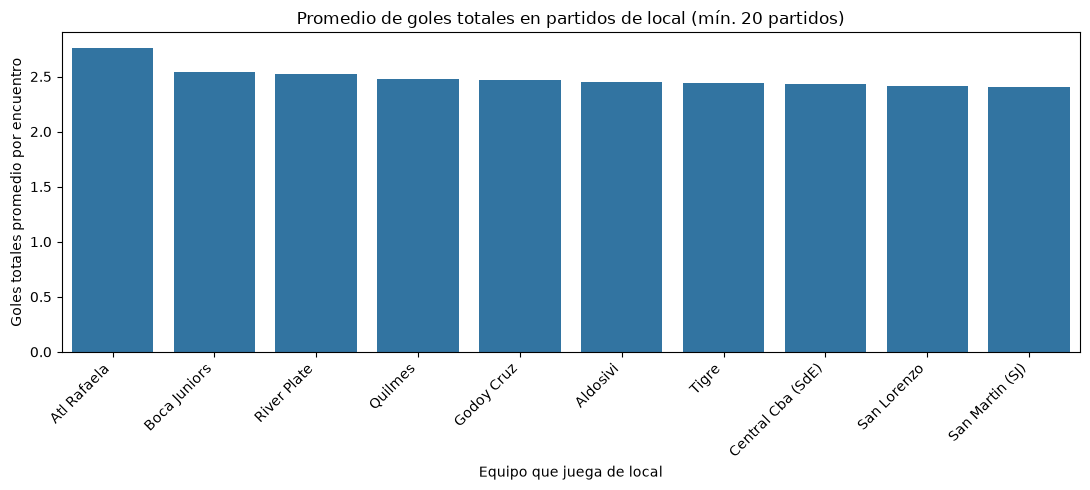

In [20]:
# Barplot construido a partir de la tabla agrupada
plt.figure(figsize=(11, 5))
sns.barplot(data=top_locales, x="team_home", y="promedio_goles", color="tab:blue")
plt.title("Promedio de goles totales en partidos de local (mín. 20 partidos)")
plt.xlabel("Equipo que juega de local")
plt.ylabel("Goles totales promedio por encuentro")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Serie temporal: evolución anual

Usamos la fecha real del partido para calcular el **promedio de goles por encuentro en cada año**. Graficamos un promedio, no la suma: así comparamos años que tuvieron distinta cantidad de partidos.

In [21]:
# Series de tiempo: agrupación por año
partidos_con_fecha = df.dropna(subset=["game_datetime"]).copy()
partidos_con_fecha["anio"] = partidos_con_fecha["game_datetime"].dt.year

resumen_anual = (
    partidos_con_fecha.groupby("anio")
    .agg(partidos=("total_goals", "count"), promedio_goles=("total_goals", "mean"))
    .reset_index()
)

resumen_anual.round(2)

,anio,partidos,promedio_goles
0,2015,448,2.21
1,2016,450,2.34
2,2017,406,2.31
3,2018,399,2.24
4,2019,328,2.27
5,2020,85,2.32
6,2021,325,2.45
7,2022,377,2.18


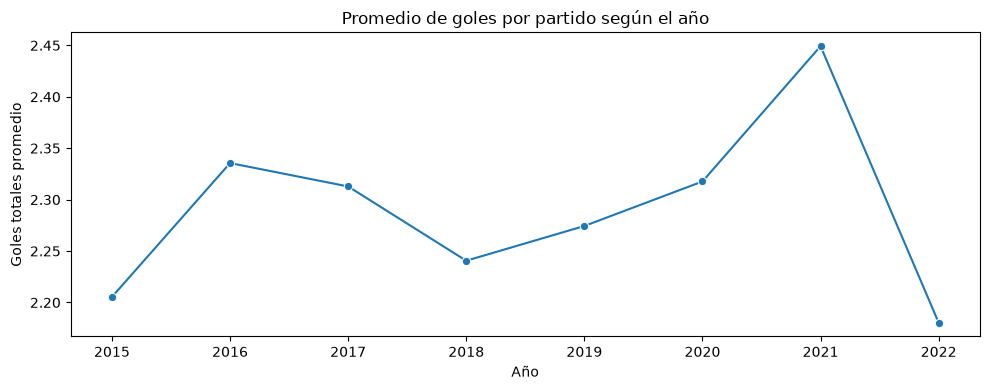

In [22]:
# Línea de tendencia a lo largo del tiempo
plt.figure(figsize=(10, 4))
sns.lineplot(data=resumen_anual, x="anio", y="promedio_goles", marker="o", color="tab:blue")
plt.title("Promedio de goles por partido según el año")
plt.xlabel("Año")
plt.ylabel("Goles totales promedio")
plt.xticks(resumen_anual["anio"])
plt.tight_layout()
plt.show()

**Interpretación:** los promedios varían entre equipos y años. Esto es descriptivo; no implica que un equipo cause más goles ni que los años tengan exactamente el mismo calendario. En particular, el número de partidos disponible en 2020 es menor, algo que conviene tener presente al interpretar la serie.

## 7. Preparar los datos para los modelos (X e y)

Ahora hacemos la parte predictiva. Definimos:

- **`X`:** 11 variables **conocidas antes del partido**: cuotas de local/empate/visitante, valor de ambos planteles, edades, alturas y proporción de jugadores zurdos.
- **`y`:** `total_goals`.

No incluimos `goals_home`, `goals_away`, `result`, posesión, tiros al arco ni faltas del mismo encuentro: **revelarían lo sucedido después del inicio del partido**.

**Limpieza para el modelo:** sacamos solo las filas sin fecha, variable objetivo o alguna de las columnas `X`. Ordenamos los partidos por fecha; de este modo los últimos encuentros pueden reservarse como prueba.


In [23]:
# Selección de partidos completos para la predicción
requeridas = ["game_datetime", "total_goals"] + columnas_x

datos_modelo = (
    df.dropna(subset=requeridas)
    .sort_values("game_datetime")
    .reset_index(drop=True)
)

print("Partidos originales:", len(df))
print("Partidos aptos para el modelo:", len(datos_modelo))
print("Partidos excluidos:", len(df) - len(datos_modelo))

datos_modelo[["game_datetime", "team_home", "team_away", "total_goals"]].head()

Partidos originales: 2821
Partidos aptos para el modelo: 2818
Partidos excluidos: 3


,game_datetime,team_home,team_away,total_goals
0,2015-02-13 18:00:00,Velez,Aldosivi,2
1,2015-02-13 21:10:00,Racing Club,Rosario Central,1
2,2015-02-14 17:00:00,San Lorenzo,Colon,2
3,2015-02-14 17:00:00,Gimnasia (LP),Def y Justicia,1
4,2015-02-14 19:15:00,Godoy Cruz,San Martin (SJ),2


In [24]:
# Variables predictoras X y variable objetivo y
X = datos_modelo[columnas_x]
y = datos_modelo["total_goals"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Variables de X:", list(X.columns))

Dimensiones de X: (2818, 11)
Dimensiones de y: (2818,)
Variables de X: ['odds_home', 'odds_draw', 'odds_away', 'team_value_home', 'team_value_away', 'mean_age_home', 'mean_age_away', 'mean_height_home', 'mean_height_away', 'lefties_proportion_home', 'lefties_proportion_away']


## 8. Separar entrenamiento y prueba

Hacemos un **split 80/20**. A diferencia de una división aleatoria, usamos `shuffle=False` sobre los datos ordenados por fecha:

- **Train (~80 %):** los partidos más antiguos; sirven para entrenar y comparar opciones.
- **Test (~20 %):** los partidos más recientes; se reservan para evaluar cuánto generaliza el modelo.

Esta elección se parece más a la situación real: **pronosticar partidos futuros con información pasada**. No elegiremos el mejor modelo usando los resultados del conjunto de test.

In [25]:
# Split temporal 80/20 usando la función vista en clase
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Último partido de entrenamiento:", datos_modelo.loc[X_train.index[-1], "game_datetime"])
print("Primer partido de prueba:", datos_modelo.loc[X_test.index[0], "game_datetime"])

Train: (2254, 11) | Test: (564, 11)
Último partido de entrenamiento: 2021-09-14 18:45:00
Primer partido de prueba: 2021-09-14 21:00:00


## 9. Baseline

Antes de entrenar modelos más elaborados necesitamos un punto de comparación (**baseline**). El baseline que usamos predice **el promedio de goles de los partidos de entrenamiento** para todos los encuentros.

In [26]:
# Modelo base: predice siempre la media de y_train
modelo_base = DummyRegressor(strategy="mean")
modelo_base.fit(X_train, y_train)

pred_base = modelo_base.predict(X_test)
print(f"El baseline predice siempre {y_train.mean():.2f} goles.")

El baseline predice siempre 2.27 goles.


## 10. Modelo 1: regresión lineal

La regresión lineal trata de predecir `total_goals` mediante una combinación de las variables de `X`. Usamos `StandardScaler` dentro de un `Pipeline` para aplicar el escalado sin calcularlo sobre test.

El `Pipeline` aprende los parámetros de escalado únicamente con los datos de **entrenamiento** y luego aplica la misma transformación a test, con el fin de evitar filtrar información de evaluación.

In [27]:
# Regresión lineal con escalado
modelo_lineal = Pipeline([
    ("escalado", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_lineal.fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)

print("Regresión lineal entrenada.")

Regresión lineal entrenada.


## 11. Modelo 2: KNN Regressor

KNN busca partidos anteriores con características parecidas y **promedia sus goles totales**. Como compara distancias entre variables, el escalado es especialmente importante: el valor de los planteles y las cuotas tienen unidades muy diferentes.

Probaremos distintos valores de `k` (cantidad de vecinos), pero **solo dentro del conjunto de entrenamiento**. incluimos `GridSearchCV`  para justificar la elección de `k` sin mirar test.

Usamos `TimeSeriesSplit` para que, durante la validación cruzada, la parte de validación quede después de la parte de entrenamiento.

In [28]:
# Pipeline: escalado + KNN
pipeline_knn = Pipeline([
    ("escalado", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

# Elegimos k con validación cruzada temporal sobre train
busqueda_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid={"knn__n_neighbors": [5, 10, 15, 25, 40]},
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error"
)

busqueda_knn.fit(X_train, y_train)
modelo_knn = busqueda_knn.best_estimator_
pred_knn = modelo_knn.predict(X_test)

print("Mejor cantidad de vecinos:", busqueda_knn.best_params_["knn__n_neighbors"])
print(f"MAE promedio de validación cruzada: {-busqueda_knn.best_score_:.3f} goles")

Mejor cantidad de vecinos: 40
MAE promedio de validación cruzada: 1.221 goles


## 12. Evaluación: MAE, RMSE y R²

Evaluamos **siempre sobre los mismos partidos de test** y comparamos baseline, regresión lineal y KNN. Vemos el **MAE (Mean Absolute Error)**, **RMSE (Root Mean Squared Error)** y **R²**


In [29]:
# Tabla de comparación de métricas
def calcular_metricas(nombre, prediccion):
    return {
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test, prediccion),
        "RMSE": np.sqrt(mean_squared_error(y_test, prediccion)),
        "R²": r2_score(y_test, prediccion)
    }

resultados = pd.DataFrame([
    calcular_metricas("Baseline (media)", pred_base),
    calcular_metricas("Regresión lineal", pred_lineal),
    calcular_metricas("KNN Regressor", pred_knn)
])

resultados.round(3)

,Modelo,MAE,RMSE,R²
0,Baseline (media),1.261,1.582,-0.002
1,Regresión lineal,1.250,1.572,0.010
2,KNN Regressor,1.261,1.589,-0.011


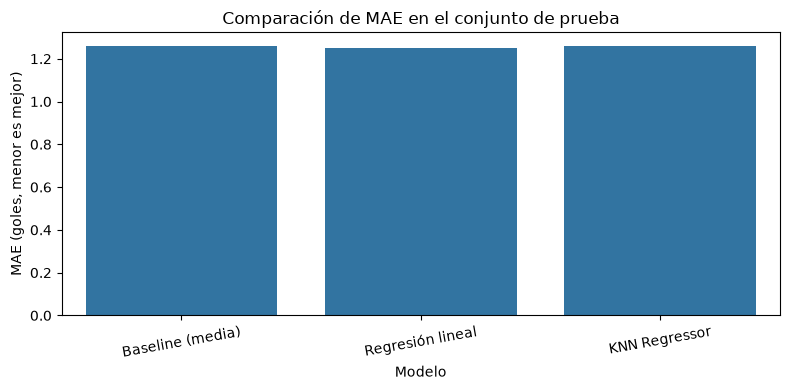

In [30]:
# Gráfico para comparar el MAE de los modelos
plt.figure(figsize=(8, 4))
sns.barplot(data=resultados, x="Modelo", y="MAE", color="tab:blue")
plt.title("Comparación de MAE en el conjunto de prueba")
plt.xlabel("Modelo")
plt.ylabel("MAE (goles, menor es mejor)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Predicciones frente a resultados reales

Mostramos algunos partidos que el modelo **no vio durante el entrenamiento**, comparando su total de goles real con las predicciones. Un modelo útil debería acercarse a la realidad de una muestra suficientemente grande, pero no se espera acertar exactamente todos los marcadores.

In [31]:
# Ejemplos de predicciones en test
comparacion_partidos = pd.DataFrame({
    "fecha": datos_modelo.loc[X_test.index, "game_datetime"].dt.strftime("%Y-%m-%d").values,
    "local": datos_modelo.loc[X_test.index, "team_home"].values,
    "visitante": datos_modelo.loc[X_test.index, "team_away"].values,
    "goles_reales": y_test.values,
    "pred_lineal": np.round(pred_lineal, 2),
    "pred_knn": np.round(pred_knn, 2)
})

comparacion_partidos.head(10)

,fecha,local,visitante,goles_reales,pred_lineal,pred_knn
0,2021-09-14,Boca Juniors,Def y Justicia,0,1.91,2.28
1,2021-09-15,Union,Estudiantes (LP),2,2.28,2.28
2,2021-09-15,Argentinos,Patronato,2,2.26,1.62
3,2021-09-15,Banfield,Rosario Central,3,2.52,2.02
4,2021-09-15,Newells,River Plate,5,2.89,2.60
5,2021-09-18,Godoy Cruz,Sarmiento (J),2,2.58,2.02
6,2021-09-18,Velez,Aldosivi,5,2.56,2.75
7,2021-09-18,Racing Club,Talleres (C),3,2.10,2.02
8,2021-09-18,Atl Tucuman,Boca Juniors,3,2.24,1.98
9,2021-09-19,Patronato,Estudiantes (LP),3,2.23,2.42


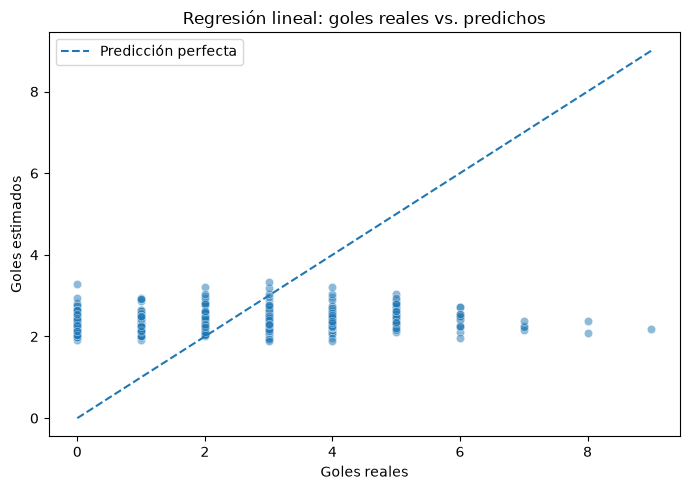

In [32]:
# Scatterplot: goles reales vs. predicción lineal
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test.values, y=pred_lineal, alpha=0.5, color="tab:blue")
plt.plot([0, 9], [0, 9], linestyle="--", label="Predicción perfecta")
plt.title("Regresión lineal: goles reales vs. predichos")
plt.xlabel("Goles reales")
plt.ylabel("Goles estimados")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Conclusiones

### ¿Qué vimos del dataset?

- Analizamos **2.821 encuentros** del fútbol argentino disputados entre 2015 y 2022; después de excluir los 3 registros sin fecha/cuotas quedaron **2.818 partidos** aptos para modelar.
- Las cifras de goles se concentran en valores bajos, con algunos partidos de muchos goles que no son errores y por eso se conservaron.
- El análisis exploratorio mostró que las cuotas, el valor del plantel y otras características previas no explican por sí solas toda la variación del total de goles.

### ¿Qué tan bien funcionaron los modelos?

En la ejecución de referencia, el **baseline** obtuvo un **MAE ≈ 1,26 goles** y **R² ≈ −0,002**. La **regresión lineal** alcanzó **MAE ≈ 1,25 goles**, **RMSE ≈ 1,57 goles** y **R² ≈ 0,01**. KNN no logró una mejora clara frente al baseline (**MAE ≈ 1,26**, **R² ligeramente negativo**). Los valores precisos se encuentran en la tabla calculada en la sección anterior.

Esto significa que, con las variables disponibles, **no conseguimos anticipar con mucha precisión el número de goles**. La mejora de la regresión lineal sobre predecir la media fue pequeña.

Aun asi, logramos notar de que este modelo no sea tan preciso se debe al factor mas importante que no es medible y que vuelve distinto al futbol y en especial al futbol argentino, el azar. al ser un deporte, por mas variables que intentemos contar, el azar juega mucho a favor, hay dias donde un equipo que tiene todo en contra puede ganarle al favorito, esto es la magia del deporte mismo. pero obviamente hay que considerar que hay mas variables que se podrian agregar para enriquecer este modelo.

### ¿En qué se equivocan y cómo mejoraríamos?

- El total de goles depende de eventos difíciles de anticipar: expulsiones, penales, lesiones y oportunidades puntuales, que hacen que una estimación promedio falle especialmente en partidos con cero o muchos goles.
- Como mejora, incorporaríamos **estadísticas históricas calculadas solo con partidos anteriores** de cada equipo (goles a favor/en contra recientes, localía y forma), nunca estadísticas del partido que queremos predecir.
- Probaríamos modelos adicionales y evaluaríamos otras temporadas para comprobar estabilidad en el tiempo.

**Conclusión general:** se cumplió el ciclo completo de ciencia de datos (carga, calidad, EDA, visualización, modelado y evaluación) y el resultado más importante es que **un modelo complejo no siempre supera de forma significativa una predicción sencilla**.